In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
import pandas as pd

data = pd.read_excel(
    r"C:\Users\Pc\Documents\pfa_stage_project\data\raw\model_data\CMO-Historical-Data-Monthly1.xlsx",
    sheet_name="Monthly Prices",
    header=4
)

# Supprimer la ligne des unités ($/mt, $/bbl, ...)
data = data.iloc[1:].reset_index(drop=True)

print(data.shape)
data.head()

(792, 72)


,Unnamed: 0,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI","Coal, Australian","Coal, South African **","Natural gas, US","Natural gas, Europe","Liquefied natural gas, Japan",...,Aluminum,"Iron ore, cfr spot",Copper,Lead,Tin,Nickel,Zinc,Gold,Platinum,Silver
0,1960M01,1.63,1.63,1.63,…,…,…,0.14,0.404774,…,...,511.471832,11.42,715.4,206.1,2180.4,1631,260.8,35.27,83.5,0.9137
1,1960M02,1.63,1.63,1.63,…,…,…,0.14,0.404774,…,...,511.471832,11.42,728.19,203.7,2180.4,1631,244.9,35.27,83.5,0.9137
2,1960M03,1.63,1.63,1.63,…,…,…,0.14,0.404774,…,...,511.471832,11.42,684.94,210.3,2173.8,1631,248.7,35.27,83.5,0.9137
3,1960M04,1.63,1.63,1.63,…,…,…,0.14,0.404774,…,...,511.471832,11.42,723.11,213.6,2178.2,1631,254.6,35.27,83.5,0.9137
4,1960M05,1.63,1.63,1.63,…,…,…,0.14,0.404774,…,...,511.471832,11.42,684.75,213.4,2162.7,1631,253.8,35.27,83.5,0.9137


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 792 entries, 0 to 791
Data columns (total 72 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Unnamed: 0                    792 non-null    object
 1   Crude oil, average            792 non-null    object
 2   Crude oil, Brent              792 non-null    object
 3   Crude oil, Dubai              792 non-null    object
 4   Crude oil, WTI                792 non-null    object
 5   Coal, Australian              792 non-null    object
 6   Coal, South African **        792 non-null    object
 7   Natural gas, US               792 non-null    object
 8   Natural gas, Europe           792 non-null    object
 9   Liquefied natural gas, Japan  792 non-null    object
 10  Natural gas index             792 non-null    object
 11  Cocoa                         792 non-null    object
 12  Coffee, Arabica               792 non-null    object
 13  Coffee, Robusta     

In [4]:
data.columns

Index(['Unnamed: 0', 'Crude oil, average', 'Crude oil, Brent',
       'Crude oil, Dubai', 'Crude oil, WTI', 'Coal, Australian',
       'Coal, South African **', 'Natural gas, US', 'Natural gas, Europe',
       'Liquefied natural gas, Japan', 'Natural gas index', 'Cocoa',
       'Coffee, Arabica', 'Coffee, Robusta', 'Tea, avg 3 auctions',
       'Tea, Colombo', 'Tea, Kolkata', 'Tea, Mombasa', 'Coconut oil',
       'Groundnuts', 'Fish meal', 'Groundnut oil **', 'Palm oil',
       'Palm kernel oil', 'Soybeans', 'Soybean oil', 'Soybean meal',
       'Rapeseed oil', 'Sunflower oil', 'Barley', 'Maize', 'Sorghum',
       'Rice, Thai 5% ', 'Rice, Thai 25% ', 'Rice, Thai A.1',
       'Rice, Viet Namese 5%', 'Wheat, US SRW', 'Wheat, US HRW',
       'Banana, Europe', 'Banana, US', 'Orange', 'Beef **', 'Chicken **',
       'Lamb **', 'Shrimps, Mexican', 'Sugar, EU', 'Sugar, US', 'Sugar, world',
       'Tobacco, US import u.v.', 'Logs, Cameroon', 'Logs, Malaysian',
       'Sawnwood, Cameroon', 'Saw

In [5]:
data=data.rename(columns={"Unnamed: 0":"Date"})

In [6]:
data.columns

Index(['Date', 'Crude oil, average', 'Crude oil, Brent', 'Crude oil, Dubai',
       'Crude oil, WTI', 'Coal, Australian', 'Coal, South African **',
       'Natural gas, US', 'Natural gas, Europe',
       'Liquefied natural gas, Japan', 'Natural gas index', 'Cocoa',
       'Coffee, Arabica', 'Coffee, Robusta', 'Tea, avg 3 auctions',
       'Tea, Colombo', 'Tea, Kolkata', 'Tea, Mombasa', 'Coconut oil',
       'Groundnuts', 'Fish meal', 'Groundnut oil **', 'Palm oil',
       'Palm kernel oil', 'Soybeans', 'Soybean oil', 'Soybean meal',
       'Rapeseed oil', 'Sunflower oil', 'Barley', 'Maize', 'Sorghum',
       'Rice, Thai 5% ', 'Rice, Thai 25% ', 'Rice, Thai A.1',
       'Rice, Viet Namese 5%', 'Wheat, US SRW', 'Wheat, US HRW',
       'Banana, Europe', 'Banana, US', 'Orange', 'Beef **', 'Chicken **',
       'Lamb **', 'Shrimps, Mexican', 'Sugar, EU', 'Sugar, US', 'Sugar, world',
       'Tobacco, US import u.v.', 'Logs, Cameroon', 'Logs, Malaysian',
       'Sawnwood, Cameroon', 'Sawnwood,

In [7]:
variables=[
  "Date",
  "Potassium chloride **",  
  "Phosphate rock",
  "DAP",
  "TSP",
  "Urea ",
  "Natural gas, US",
  "Natural gas, Europe",
  "Crude oil, Brent"

]
df=data[variables].copy()

In [8]:
df=df.rename(columns={
"Potassium chloride **": "KCL",
"Crude oil, Brent":"Brent",
"Natural gas, US":"Gas_US",
"Natural gas, Europe":"Gas_EUR",
"Phosphate rock":"Phosphate",
"Urea ":"Urea"
})

In [9]:
df.columns

Index(['Date', 'KCL', 'Phosphate', 'DAP', 'TSP', 'Urea', 'Gas_US', 'Gas_EUR',
       'Brent'],
      dtype='object')

In [10]:
df.dtypes

Date         object
KCL          object
Phosphate    object
DAP          object
TSP          object
Urea         object
Gas_US       object
Gas_EUR      object
Brent        object
dtype: object

In [11]:
df["Date"]=pd.to_datetime(df["Date"],format="%YM%m")

In [12]:
for col in df.columns[1:]:
    df[col]=pd.to_numeric(df[col],errors="coerce")

In [13]:

df.dtypes

Date         datetime64[ns]
KCL                 float64
Phosphate           float64
DAP                 float64
TSP                 float64
Urea                float64
Gas_US              float64
Gas_EUR             float64
Brent               float64
dtype: object

In [14]:
df=df.replace("…",np.nan)
df = df.replace("...", np.nan)

In [15]:
df.isna().sum()

Date          0
KCL           0
Phosphate     1
DAP          84
TSP           0
Urea          0
Gas_US        0
Gas_EUR       0
Brent         0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df[df["DAP"].notna()][["Date", "DAP"]].head()

,Date,DAP
84,1967-01-01,68.5
85,1967-02-01,68.5
86,1967-03-01,68.5
87,1967-04-01,68.5
88,1967-05-01,68.5


In [18]:
df=df.dropna()

In [19]:
df.isna().sum()

Date         0
KCL          0
Phosphate    0
DAP          0
TSP          0
Urea         0
Gas_US       0
Gas_EUR      0
Brent        0
dtype: int64

In [20]:
df.head()

,Date,KCL,Phosphate,DAP,TSP,Urea,Gas_US,Gas_EUR,Brent
84,1967-01-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
85,1967-02-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
86,1967-03-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
87,1967-04-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
88,1967-05-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33


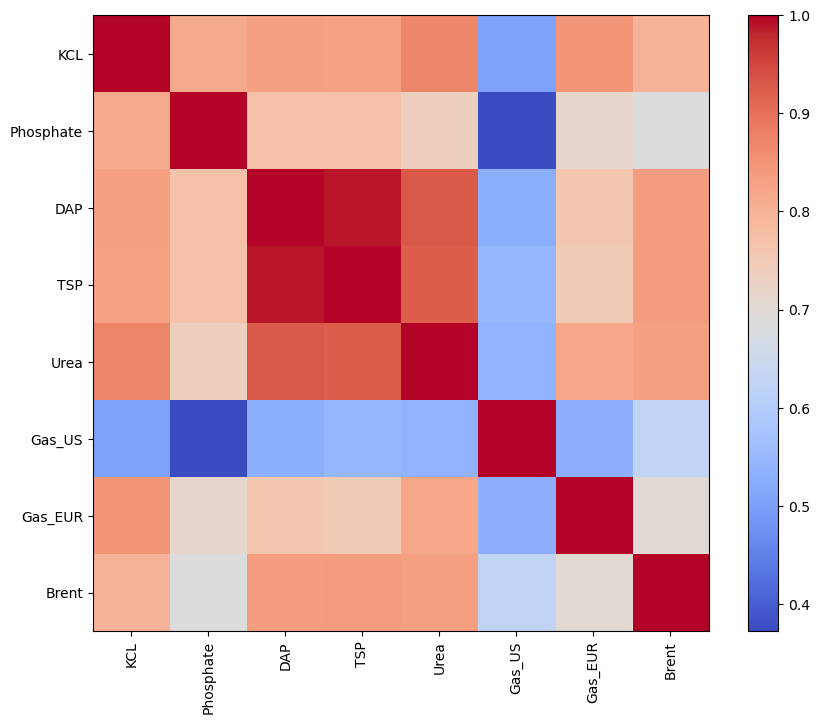

In [21]:
#correlation  entre les variables
corr=df.drop(columns="Date").corr()
plt.figure(figsize=(10,8))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.show()

In [22]:
corr = df.drop(columns="Date").corr()

print(corr)

                KCL  Phosphate       DAP       TSP      Urea    Gas_US  \
KCL        1.000000   0.813736  0.833201  0.830480  0.871528  0.503871   
Phosphate  0.813736   1.000000  0.771121  0.771353  0.733577  0.372474   
DAP        0.833201   0.771121  1.000000  0.987964  0.929695  0.528714   
TSP        0.830480   0.771353  0.987964  1.000000  0.923293  0.545750   
Urea       0.871528   0.733577  0.929695  0.923293  1.000000  0.537307   
Gas_US     0.503871   0.372474  0.528714  0.545750  0.537307  1.000000   
Gas_EUR    0.846527   0.710765  0.758970  0.748666  0.820583  0.529386   
Brent      0.798863   0.685764  0.834963  0.837116  0.831829  0.627170   

            Gas_EUR     Brent  
KCL        0.846527  0.798863  
Phosphate  0.710765  0.685764  
DAP        0.758970  0.834963  
TSP        0.748666  0.837116  
Urea       0.820583  0.831829  
Gas_US     0.529386  0.627170  
Gas_EUR    1.000000  0.701755  
Brent      0.701755  1.000000  


In [23]:
#selectionner les variables explicatives
X = df[
    [
        "Phosphate",
        "DAP",
        "TSP",
        "Urea",
        "Gas_US",
        "Gas_EUR",
        "Brent"
    ]
].copy()

In [24]:
def calculate_vif(X):
    vif=pd.DataFrame()
    vif["Variable"]=X.columns
    vif["VIF"]=[
        variance_inflation_factor(X.values,i)
        for i in range(X.shape[1])
    ]
    return vif.sort_values(by="VIF",ascending=False)

In [25]:
#afficher le premier vif
vif = calculate_vif(X)

print(vif)

    Variable         VIF
1        DAP  111.968041
2        TSP  100.810297
3       Urea   27.433135
6      Brent   10.344932
5    Gas_EUR    5.742141
0  Phosphate    5.630685
4     Gas_US    3.921276


In [26]:
X = X.drop(columns=["TSP"])

vif = calculate_vif(X)
print(vif)

    Variable        VIF
2       Urea  27.366854
1        DAP  26.127418
5      Brent  10.266380
4    Gas_EUR   5.739250
0  Phosphate   5.557885
3     Gas_US   3.920838


In [71]:
X = X.drop(columns=["Urea"])

vif = calculate_vif(X)
print(vif)

    Variable        VIF
1        DAP  11.785804
4      Brent   9.779685
0  Phosphate   5.487565
3    Gas_EUR   4.555016
2     Gas_US   3.917953


In [ ]:
df_check=df.to_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\cleaned_data.csv",index=False)